# Hito 2 · NextLap · Executed experiment, error analysis and SHAP

**IIT414W · Team Lab 8.** Executes the plan written in `Hito1/HITO1.md` (section 4):

| Version | Inputs | Role |
|---|---|---|
| (a) OLS reference | 6 published inputs | baseline |
| (b) matched control | (a) + `has_history2` | candidate with the spread removed |
| (c) candidate | (b) + `recent_std_s` | **(c) vs (b) isolates the spread** |

Run: `jupyter nbconvert --to notebook --execute --inplace Hito2/hito2_experiment.ipynb` (or **Run All**).
Data: `W09_StudentPack_v2/base_NextLap` (git-ignored) or `$NEXTLAP_DATA`. Every number in `HITO2.md` is written by this notebook to `outputs/`.
The course helper `nextlap_reference_v1.py` is used unmodified (with attribution). No test data are read. `RANDOM_SEED = 414`.

## 0. Setup and data location

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

HITO = Path.cwd() if (Path.cwd() / "hito2_experiment.ipynb").is_file() else Path.cwd() / "Hito2"
HITO = HITO.resolve()
REPO = HITO.parent
DATA_DIR = Path(os.environ.get("NEXTLAP_DATA", REPO / "W09_StudentPack_v2" / "base_NextLap")).resolve()
OUT = HITO / "outputs"
RANDOM_SEED = 414
TOL = 1e-9  # seconds

assert (DATA_DIR / "train_clean_v1.csv").is_file(), f"Course data not found at {DATA_DIR}. See Hito2/README.md."
sys.path.insert(0, str(DATA_DIR))
import nextlap_reference_v1 as R  # noqa: E402  course helper, used as released

np.random.seed(RANDOM_SEED)
OUT.mkdir(exist_ok=True)
KEYS = R.KEYS                       # season, round, driver_number
STINT_KEYS = KEYS + ["stint"]


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def mae(y, p) -> float:
    return float(np.mean(np.abs(np.asarray(y, float) - np.asarray(p, float))))


def save(df: pd.DataFrame, name: str) -> None:
    """Only the row-level predictions are saved as a file; every other table is shown in this notebook."""
    df.to_csv(OUT / name, index=False)
    print(f"  wrote outputs/{name} ({len(df)} rows)")

## 1. Data and fixed comparison

In [2]:
print("1. Loading released data")
raw, manifest = R.load_snapshots(DATA_DIR)          # verifies the SHA-256 of each lap snapshot
train = pd.read_csv(DATA_DIR / "train_clean_v1.csv", dtype={"driver_number": str})
val = pd.read_csv(DATA_DIR / "validation_clean_v1.csv", dtype={"driver_number": str})

assert len(train) == 5772 and len(val) == 1808
assert sorted(train["round"].unique()) == list(range(1, 8)) and sorted(val["round"].unique()) == [8, 9]
assert val["round"].eq(8).sum() == 1066 and val["round"].eq(9).sum() == 742
assert train.pair_id.is_unique and val.pair_id.is_unique and not set(train.pair_id) & set(val.pair_id)
assert train.clean_pair.all() and val.clean_pair.all()
split_table = pd.concat([
    train.groupby(["round", "event_name"]).size().rename("rows").reset_index().assign(split="train"),
    val.groupby(["round", "event_name"]).size().rename("rows").reset_index().assign(split="validation"),
])[["split", "round", "event_name", "rows"]]

split_table

1. Loading released data


,split,round,event_name,rows
0,train,1,Australian Grand Prix,752
1,train,2,Chinese Grand Prix,635
2,train,3,Japanese Grand Prix,867
3,train,4,Miami Grand Prix,688
4,train,5,Canadian Grand Prix,787
5,train,6,Monaco Grand Prix,1107
6,train,7,Barcelona Grand Prix,936
0,validation,8,Austrian Grand Prix,1066
1,validation,9,British Grand Prix,742


## 2. Proposed input, built on the ORIGINAL lap timeline (before the clean-pair filter)

In [3]:
def history_features(laps: pd.DataFrame, window: int = 3, min_laps: int = 2) -> pd.DataFrame:
    """Per driver-lap history using laps <= t only, within driver, race and stint.

    Same clean-lap rule and window as the course helper's recent_mean_s
    (R.build_pairs): laps that are not clean are left out of the window.
    """
    d = laps.sort_values(KEYS + ["lap_number"]).reset_index(drop=True).copy()
    d["current_clean"] = (d.lap_number.gt(1) & d.lap_time_s.gt(0) & d.is_accurate & ~d.pit_in
                          & ~d.pit_out & ~d.deleted & d.track_status.eq("1"))
    d["history_value"] = d.lap_time_s.where(d.current_clean)
    d["history_end"] = d.end_time_s.where(d.current_clean)
    g = d.groupby(STINT_KEYS, dropna=False, sort=False)
    roll = lambda col, fn: g[col].transform(lambda s: getattr(s.rolling(window, min_periods=1), fn)())
    d["mean_check_s"] = roll("history_value", "mean")
    d["count_check"] = roll("history_value", "count")
    d["recent_std_s"] = g["history_value"].transform(
        lambda s: s.rolling(window, min_periods=min_laps).std(ddof=1))
    d["last_obs_end_s"] = roll("history_end", "max")     # latest timestamp the window used
    d["has_history2"] = (d["count_check"] >= min_laps).astype(int)
    d["pair_id"] = (d.season.astype(str) + "-R" + d["round"].astype(str) + "-" + d.driver_number
                    + "-L" + d.lap_number.astype(int).astype(str))
    return d[["pair_id", "season", "round", "driver_number", "lap_number", "end_time_s",
              "mean_check_s", "count_check", "recent_std_s", "has_history2", "last_obs_end_s"]]


print("2. Building recent_std_s on the original timeline")
hist = history_features(raw)
assert hist.pair_id.is_unique


def attach(frame: pd.DataFrame, h: pd.DataFrame) -> pd.DataFrame:
    out = frame.merge(h.drop(columns=["season", "round", "driver_number"]).rename(columns={"end_time_s": "raw_end_time_s"}), on="pair_id",
                      how="left", validate="one_to_one", indicator=True)
    assert out["_merge"].eq("both").all(), "a pair_id has no row in the original timeline"
    assert len(out) == len(frame) and out.pair_id.tolist() == frame.pair_id.tolist()
    assert (out.raw_end_time_s - out.end_time_s).abs().max() < TOL      # same lap t in both sources
    return out.drop(columns="_merge")


train, val = attach(train, hist), attach(val, hist)

2. Building recent_std_s on the original timeline


## 3. Checks written in Hito 1 (HITO1.md section 4), run before any extension MAE

In [4]:
print("3. Pre-registered checks")
checks = {"defined_in": "Hito1/HITO1.md section 4 (commit 453863d), before implementation"}

# C1 · our window == the released recent_mean_s / recent_count
both = pd.concat([train, val])
d_mean = float((both.mean_check_s - both.recent_mean_s).abs().max())
d_count = int((both.count_check != both.recent_count).sum())
checks["1_window_matches_released_recent_mean"] = {
    "rows": len(both), "max_abs_diff_s": d_mean, "count_mismatches": d_count,
    "passed": bool(d_mean < TOL and d_count == 0)}

# C2 · removing every lap after t does not change the feature (random training sample + validation sample)
rng = np.random.default_rng(RANDOM_SEED)
sample = pd.concat([train.iloc[rng.choice(len(train), 500, replace=False)],
                    val.iloc[rng.choice(len(val), 200, replace=False)]])
raw_by_driver = {k: g for k, g in raw.groupby(["round", "driver_number"])}
changed = 0
for row in sample.itertuples():
    laps = raw_by_driver[(row.round, row.driver_number)]
    truncated = history_features(laps[laps.lap_number <= row.current_lap_number])
    t = truncated.loc[truncated.pair_id == row.pair_id].iloc[0]
    same_std = (np.isnan(t.recent_std_s) and np.isnan(row.recent_std_s)) or abs(t.recent_std_s - row.recent_std_s) < TOL
    changed += int(not (same_std and t.has_history2 == row.has_history2))
checks["2_truncation_after_t"] = {"rows_tested": len(sample), "train_rows": 500, "validation_rows": 200,
                                  "seed": RANDOM_SEED, "rows_changed": changed, "passed": changed == 0}

# C3 · last observation used ends at or before end_time_s of t
late = int((both.last_obs_end_s > both.end_time_s + TOL).sum())
checks["3_last_observation_at_or_before_t"] = {
    "rows": len(both), "rows_after_t": late,
    "max_last_obs_minus_end_t_s": float((both.last_obs_end_s - both.end_time_s).max()), "passed": late == 0}

# C4 · every row has a value or the declared fallback; pair_id sets unchanged
cov = []
for name, f in [("train", train), ("validation", val), ("validation_R8", val[val["round"] == 8]),
                ("validation_R9", val[val["round"] == 9])]:
    cov.append({"population": name, "rows": len(f), "recent_std_observed": int(f.recent_std_s.notna().sum()),
                "short_history_fallback": int(f.recent_std_s.isna().sum()),
                "coverage_pct": round(100 * f.recent_std_s.notna().mean(), 2),
                "has_history2_eq_0": int((f.has_history2 == 0).sum())})
coverage = pd.DataFrame(cov)
assert (coverage.short_history_fallback == coverage.has_history2_eq_0).all()
checks["4_coverage_and_row_identity"] = {
    "train_rows": len(train), "validation_rows": len(val),
    "short_history_train": int(train.recent_std_s.isna().sum()),
    "short_history_validation": int(val.recent_std_s.isna().sum()),
    "fallback_rule": "missing recent_std_s -> training median (SimpleImputer fitted on train only) + has_history2 = 0",
    "passed": bool(len(train) == 5772 and len(val) == 1808)}
assert all(c["passed"] for k, c in checks.items() if k[0].isdigit()), checks
print("  all four checks passed")

print(json.dumps(checks, indent=1))
coverage

3. Pre-registered checks


  all four checks passed
{
 "defined_in": "Hito1/HITO1.md section 4 (commit 453863d), before implementation",
 "1_window_matches_released_recent_mean": {
  "rows": 7580,
  "max_abs_diff_s": 1.4210854715202004e-14,
  "count_mismatches": 0,
  "passed": true
 },
 "2_truncation_after_t": {
  "rows_tested": 700,
  "train_rows": 500,
  "validation_rows": 200,
  "seed": 414,
  "rows_changed": 0,
  "passed": true
 },
 "3_last_observation_at_or_before_t": {
  "rows": 7580,
  "rows_after_t": 0,
  "max_last_obs_minus_end_t_s": 0.0,
  "passed": true
 },
 "4_coverage_and_row_identity": {
  "train_rows": 5772,
  "validation_rows": 1808,
  "short_history_train": 456,
  "short_history_validation": 148,
  "fallback_rule": "missing recent_std_s -> training median (SimpleImputer fitted on train only) + has_history2 = 0",
  "passed": true
 }
}


,population,rows,recent_std_observed,short_history_fallback,coverage_pct,has_history2_eq_0
0,train,5772,5316,456,92.10,456
1,validation,1808,1660,148,91.81,148
2,validation_R8,1066,984,82,92.31,82
3,validation_R9,742,676,66,91.11,66


## 4. Fit (a) reference, (b) matched control, (c) candidate — training rows only

In [5]:
print("4. Fitting the three OLS versions on training rows only")
VERSIONS = {
    "a_OLS_reference": R.NUMERIC,
    "b_matched_control": R.NUMERIC + ["has_history2"],
    "c_candidate": R.NUMERIC + ["has_history2", "recent_std_s"],
}
models, preds = {}, {}
for name, numeric in VERSIONS.items():
    m = R.make_model("OLS", numeric=numeric, categorical=R.CATEGORICAL)
    m.fit(train[numeric + R.CATEGORICAL], train[R.TARGET])          # imputer/scaler/encoder fitted here, on train
    models[name], preds[name] = m, m.predict(val[numeric + R.CATEGORICAL])
    assert np.isfinite(preds[name]).all()
fill_value = float(models["c_candidate"].named_steps["prepare"].named_transformers_["numeric"]
                   .named_steps["fill"].statistics_[-1])
assert abs(fill_value - train.recent_std_s.median()) < TOL     # fallback = training median

# Reference reproduces Hito 1 (and the instructor's file, when the course pack is present)
h1 = pd.read_csv(REPO / "Hito1" / "outputs" / "validation_reference_predictions.csv")
mm = val[["pair_id"]].assign(ours=preds["a_OLS_reference"]).merge(h1, on="pair_id", validate="one_to_one")
assert len(mm) == 1808
ref_check = {"hito1_rows_matched": len(mm), "hito1_max_abs_diff_s": float((mm.ours - mm.OLS_reference).abs().max())}
inst = DATA_DIR.parent / "salidas_referencia" / "validation_reference_predictions.csv"
if inst.is_file():
    mi = val[["pair_id"]].assign(ours=preds["a_OLS_reference"]).merge(pd.read_csv(inst), on="pair_id", validate="one_to_one")
    ref_check.update({"instructor_rows_matched": len(mi), "instructor_sha256": sha256(inst),
                      "instructor_max_abs_diff_s": float((mi.ours - mi.OLS_reference).abs().max())})
assert all(v < TOL for k, v in ref_check.items() if k.endswith("diff_s"))

# Row-level predictions with identities
pred_table = val[["pair_id", "round", "event_name", "driver_number", "current_lap_number", "current_compound",
                  "current_tyre_life", "recent_count", "has_history2", "recent_std_s", "current_lap_s",
                  "recent_mean_s"]].copy()
pred_table["y_true_s"] = val[R.TARGET].to_numpy()
for name in VERSIONS:
    pred_table[f"pred_{name}"] = preds[name]
    pred_table[f"abserr_{name}"] = (pred_table.y_true_s - preds[name]).abs()
assert pred_table.pair_id.is_unique and len(pred_table) == 1808
save(pred_table, "validation_predictions.csv")

pd.DataFrame([ref_check])

4. Fitting the three OLS versions on training rows only


  wrote outputs/validation_predictions.csv (1808 rows)


,hito1_rows_matched,hito1_max_abs_diff_s,instructor_rows_matched,instructor_sha256,instructor_max_abs_diff_s
0,1808,4.263256e-14,1808,bfb25abbae32f9785c3db01ff7c0b1260499350deb2921...,2.842171e-14


## 5. Metrics, ablation, race table

In [6]:
print("5. Metrics")
POPS = [("all_validation", np.ones(len(val), bool)), ("round_8", val["round"].eq(8).to_numpy()),
        ("round_9", val["round"].eq(9).to_numpy())]
rows = [{"version": n, "inputs": " + ".join(f for f in VERSIONS[n] + R.CATEGORICAL), "population": p,
         "n": int(msk.sum()), "MAE_s": mae(val.loc[msk, R.TARGET], preds[n][msk])}
        for n in VERSIONS for p, msk in POPS]
metrics = pd.DataFrame(rows)

piv = metrics.pivot(index="population", columns="version", values="MAE_s")
nn = metrics.groupby("population").n.first()
race = pd.DataFrame({
    "population": piv.index, "n": nn[piv.index].to_numpy(),
    "MAE_reference_s": piv["a_OLS_reference"].to_numpy(),
    "MAE_control_s": piv["b_matched_control"].to_numpy(),
    "MAE_candidate_s": piv["c_candidate"].to_numpy()})
race["control_minus_candidate_s"] = race.MAE_control_s - race.MAE_candidate_s
race["reference_minus_candidate_s"] = race.MAE_reference_s - race.MAE_candidate_s
race["reference_minus_control_s"] = race.MAE_reference_s - race.MAE_control_s
r8, r9, al = (race.set_index("population").loc[k] for k in ["round_8", "round_9", "all_validation"])
pooled = {c: float((r8[c] * r8.n + r9[c] * r9.n) / (r8.n + r9.n)) for c in
          ["MAE_reference_s", "MAE_control_s", "MAE_candidate_s", "control_minus_candidate_s"]}
for c, v in pooled.items():
    assert abs(v - al[c]) < TOL, c        # row-weighted pooling reproduces the overall value

# Paired cluster bootstrap of (control - candidate) MAE: resample whole driver-races (seed 414)
clusters = pred_table.groupby(["round", "driver_number"]).indices
keys = list(clusters)
d_err = (pred_table.abserr_b_matched_control - pred_table.abserr_c_candidate).to_numpy()
rng = np.random.default_rng(RANDOM_SEED)
boot = []
for _ in range(2000):
    idx = np.concatenate([clusters[keys[i]] for i in rng.integers(0, len(keys), len(keys))])
    boot.append(d_err[idx].mean())
boot = np.array(boot)
bootstrap = {"statistic": "MAE_control - MAE_candidate (s), all validation", "observed_s": float(d_err.mean()),
             "resampling_unit": "driver-race (round, driver_number)", "clusters": len(keys), "reps": 2000,
             "seed": RANDOM_SEED, "ci95_low_s": float(np.percentile(boot, 2.5)),
             "ci95_high_s": float(np.percentile(boot, 97.5)), "share_reps_positive": float((boot > 0).mean())}

# Pre-registered decision rule (HITO1.md section 4)
rule = {
    "supports_if": "MAE(c) < MAE(a) and MAE(c) < MAE(b), overall AND in round 8 AND in round 9",
    "c_below_a": {p: bool(race.set_index("population").loc[p, "reference_minus_candidate_s"] > 0) for p in race.population},
    "c_below_b": {p: bool(race.set_index("population").loc[p, "control_minus_candidate_s"] > 0) for p in race.population},
}
rule["hypothesis_supported"] = bool(all(rule["c_below_a"].values()) and all(rule["c_below_b"].values()))

display(race.round(4))
print(json.dumps(rule, indent=1))
print(json.dumps(bootstrap, indent=1))

5. Metrics


,population,n,MAE_reference_s,MAE_control_s,MAE_candidate_s,control_minus_candidate_s,reference_minus_candidate_s,reference_minus_control_s
0,all_validation,1808,0.3867,0.3877,0.3697,0.0179,0.0170,-0.0010
1,round_8,1066,0.3736,0.3716,0.3588,0.0128,0.0148,0.0019
2,round_9,742,0.4056,0.4107,0.3854,0.0253,0.0201,-0.0051


{
 "supports_if": "MAE(c) < MAE(a) and MAE(c) < MAE(b), overall AND in round 8 AND in round 9",
 "c_below_a": {
  "all_validation": true,
  "round_8": true,
  "round_9": true
 },
 "c_below_b": {
  "all_validation": true,
  "round_8": true,
  "round_9": true
 },
 "hypothesis_supported": true
}
{
 "statistic": "MAE_control - MAE_candidate (s), all validation",
 "observed_s": 0.017940776781099902,
 "resampling_unit": "driver-race (round, driver_number)",
 "clusters": 43,
 "reps": 2000,
 "seed": 414,
 "ci95_low_s": 0.008893244412764517,
 "ci95_high_s": 0.02814973899957585,
 "share_reps_positive": 1.0
}


## 6. Error slices (declared definitions)

In [7]:
print("6. Error slices")
q1, q2 = np.nanquantile(train.recent_std_s, [1 / 3, 2 / 3])   # thresholds from TRAINING distribution
pt = pred_table
pt["slice_history"] = np.where(pt.has_history2 == 1, "history>=2 clean laps", "short history (1 clean lap)")
pt["slice_spread"] = np.select(
    [pt.recent_std_s.isna(), pt.recent_std_s <= q1, pt.recent_std_s <= q2],
    ["no spread (short history)", f"low spread (<= {q1:.3f} s)", f"mid spread ({q1:.3f}-{q2:.3f} s]"],
    f"high spread (> {q2:.3f} s)")
slices = []
for col in ["slice_history", "slice_spread", "current_compound"]:
    for (rnd, val_), g in pt.groupby([np.where(pt["round"] == 8, "R8", "R9"), col]):
        for rlab, gg in [(rnd, g)]:
            slices.append({"slice_type": col, "slice": val_, "race": rlab, "n": len(gg),
                           "MAE_control_s": gg.abserr_b_matched_control.mean(),
                           "MAE_candidate_s": gg.abserr_c_candidate.mean(),
                           "control_minus_candidate_s": gg.abserr_b_matched_control.mean() - gg.abserr_c_candidate.mean()})
    for val_, gg in pt.groupby(col):
        slices.append({"slice_type": col, "slice": val_, "race": "R8+R9", "n": len(gg),
                       "MAE_control_s": gg.abserr_b_matched_control.mean(),
                       "MAE_candidate_s": gg.abserr_c_candidate.mean(),
                       "control_minus_candidate_s": gg.abserr_b_matched_control.mean() - gg.abserr_c_candidate.mean()})
slices = pd.DataFrame(slices)

slices.round(4)

6. Error slices


,slice_type,slice,race,n,MAE_control_s,MAE_candidate_s,control_minus_candidate_s
0,slice_history,history>=2 clean laps,R8,984,0.3707,0.3571,0.0135
1,slice_history,short history (1 clean lap),R8,82,0.3830,0.3786,0.0045
2,slice_history,history>=2 clean laps,R9,676,0.3998,0.3697,0.0300
3,slice_history,short history (1 clean lap),R9,66,0.5230,0.5464,-0.0234
4,slice_history,history>=2 clean laps,R8+R9,1660,0.3825,0.3623,0.0202
5,slice_history,short history (1 clean lap),R8+R9,148,0.4455,0.4534,-0.0080
6,slice_spread,high spread (> 0.403 s),R8,234,0.5435,0.4646,0.0789
7,slice_spread,low spread (<= 0.170 s),R8,395,0.2994,0.3041,-0.0047
8,slice_spread,mid spread (0.170-0.403 s],R8,355,0.3361,0.3453,-0.0092
9,slice_spread,no spread (short history),R8,82,0.3830,0.3786,0.0045


## 7. Inspected validation case

Rule (fixed before looking at it): the validation row where adding the spread moved the
prediction the most, |pred_c - pred_b|. That is where the new input matters most.

In [8]:
pt["shift_c_minus_b_s"] = pt.pred_c_candidate - pt.pred_b_matched_control
case_row = pt.loc[pt.shift_c_minus_b_s.abs().idxmax()]
case_id = case_row.pair_id
laps = raw[(raw["round"] == case_row["round"]) & (raw.driver_number == case_row.driver_number)
           & raw.lap_number.between(case_row.current_lap_number - 4, case_row.current_lap_number + 1)]
case_laps = laps[["lap_number", "lap_time_s", "stint", "compound", "tyre_life", "track_status",
                  "is_accurate", "pit_in", "pit_out", "deleted"]].copy()
case_laps["role"] = np.where(case_laps.lap_number == case_row.current_lap_number, "t",
                     np.where(case_laps.lap_number == case_row.current_lap_number + 1, "t+1 (target, not an input)", "history"))
case = {k: (v.item() if hasattr(v, "item") else v) for k, v in case_row[
    ["pair_id", "round", "event_name", "driver_number", "current_lap_number", "current_compound", "current_tyre_life",
     "current_lap_s", "recent_mean_s", "recent_count", "recent_std_s", "y_true_s", "pred_a_OLS_reference",
     "pred_b_matched_control", "pred_c_candidate", "abserr_a_OLS_reference", "abserr_b_matched_control",
     "abserr_c_candidate", "shift_c_minus_b_s"]].items()}
case["selection_rule"] = "validation row with the largest |pred_c - pred_b|"
case["check_abs_error_c"] = abs(case["y_true_s"] - case["pred_c_candidate"])

display(case_laps)
pd.Series(case)

,lap_number,lap_time_s,stint,compound,tyre_life,track_status,is_accurate,pit_in,pit_out,deleted,role
9681,3.0,95.816,2.0,HARD,2.0,1,True,False,False,False,history
9682,4.0,96.460,2.0,HARD,3.0,1,True,False,False,False,history
9683,5.0,96.299,2.0,HARD,4.0,1,True,False,False,False,history
9684,6.0,98.070,2.0,HARD,5.0,1,True,False,False,False,history
9685,7.0,105.128,2.0,HARD,6.0,1,True,False,False,False,t
9686,8.0,97.882,2.0,HARD,7.0,1,True,False,False,False,"t+1 (target, not an input)"


pair_id                                                         2026-R9-23-L7
round                                                                       9
event_name                                                 British Grand Prix
driver_number                                                              23
current_lap_number                                                        7.0
current_compound                                                         HARD
current_tyre_life                                                         6.0
current_lap_s                                                         105.128
recent_mean_s                                                       99.832333
recent_count                                                              3.0
recent_std_s                                                         4.670886
y_true_s                                                               97.882
pred_a_OLS_reference                                            

## 8. SHAP (LinearExplainer, interventional, training background)

8. SHAP


/sessions/rcw-01tsodvv3phflxlyzgyv1z41/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


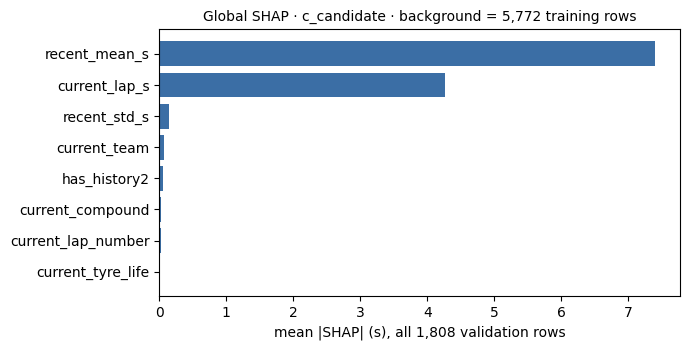

/sessions/rcw-01tsodvv3phflxlyzgyv1z41/tmp/ipykernel_13/413770349.py:71: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv.values[:, num_idx], Xval[:, num_idx], feature_names=[n for n, k in zip(enc_names, num_idx) if k],


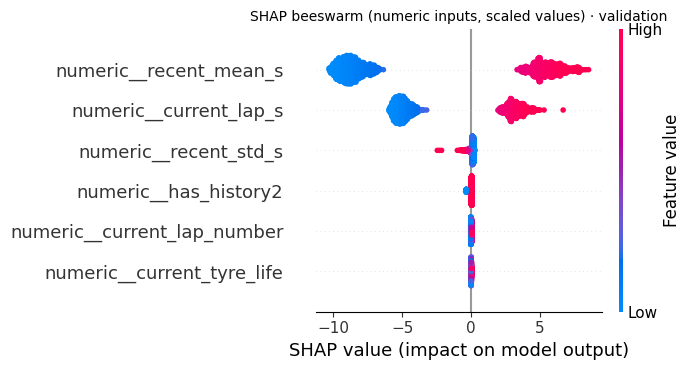

,original_input,value_at_t,shap_contribution_s
0,current_lap_s,105.128,6.6680
1,recent_mean_s,99.832333,8.1826
2,current_lap_number,7.0,-0.0315
3,current_tyre_life,6.0,-0.0122
4,has_history2,1,0.0308
5,recent_std_s,4.670886,-2.4671
6,current_compound,HARD,0.0425
7,current_team,Williams,-0.0268
8,BASE (mean training prediction),NaN,86.7343
9,BASE + contributions,NaN,99.1207


,original_input,mean_abs_shap_s_all_1808,mean_abs_shap_s_R8_1066,mean_abs_shap_s_R9_742,mean_signed_shap_s_all
1,recent_mean_s,7.4049,8.7036,5.5390,-2.8585
0,current_lap_s,4.2725,5.0050,3.2202,-1.6294
5,recent_std_s,0.1490,0.1499,0.1478,0.0494
7,current_team,0.0642,0.0589,0.0718,-0.0041
4,has_history2,0.0576,0.0560,0.0599,-0.0011
6,current_compound,0.0314,0.0367,0.0236,0.0069
2,current_lap_number,0.0217,0.0250,0.0170,-0.0004
3,current_tyre_life,0.0080,0.0079,0.0081,-0.0047


{
 "model": "c_candidate",
 "pair_id": "2026-R9-23-L7",
 "base_value_s": 86.7343023215523,
 "sum_contributions_s": 12.386385592450186,
 "prediction_s": 99.12068791400249,
 "reconstruction_error_s": 0.0,
 "observed_s": 97.882,
 "abs_error_s": 1.2386879140024831
}


In [9]:
print("8. SHAP")
import shap  # noqa: E402
import matplotlib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402

EXPLAINED = os.environ.get("SHAP_MODEL", "c_candidate")
model = models[EXPLAINED]
cols = VERSIONS[EXPLAINED] + R.CATEGORICAL
prep, reg = model.named_steps["prepare"], model.named_steps["regression"]
enc_names = list(prep.get_feature_names_out())
Xbg = prep.transform(train[cols])              # background = ALL training rows (transform fitted on train)
Xval = prep.transform(val[cols])
explainer = shap.LinearExplainer(reg, shap.maskers.Independent(Xbg, max_samples=len(Xbg)))
sv = explainer(Xval)
base = float(np.atleast_1d(sv.base_values)[0])
assert np.allclose(sv.base_values, base)

# independent cross-check of the explainer: phi_j = coef_j * (x_j - mean_bg_j)
manual = reg.coef_ * (Xval - Xbg.mean(0))
shap_check = {"max_abs_diff_shap_vs_coef_formula": float(np.abs(sv.values - manual).max()),
              "base_vs_mean_train_prediction_s": float(abs(base - model.predict(train[cols]).mean()))}
recon = base + sv.values.sum(1)
shap_check["max_abs_reconstruction_error_s"] = float(np.abs(recon - model.predict(val[cols])).max())
assert shap_check["max_abs_reconstruction_error_s"] < 1e-6


def original_input(enc: str) -> str:
    name = enc.split("__", 1)[1]
    for c in R.CATEGORICAL:
        if name.startswith(c + "_"):
            return c
    return name


mapping = pd.DataFrame({"encoded_input": enc_names, "original_input": [original_input(e) for e in enc_names],
                        "coefficient_s_per_unit": reg.coef_, "background_mean": Xbg.mean(0)})
groups = list(dict.fromkeys(mapping.original_input))
G = np.column_stack([sv.values[:, mapping.original_input.eq(g).to_numpy()].sum(1) for g in groups])

# Local explanation: the inspected case
i = int(np.flatnonzero(val.pair_id.to_numpy() == case_id)[0])
local = pd.DataFrame({"original_input": groups, "value_at_t": [val.iloc[i][g] for g in groups],
                      "shap_contribution_s": G[i]})
local = pd.concat([local, pd.DataFrame([
    {"original_input": "BASE (mean training prediction)", "value_at_t": np.nan, "shap_contribution_s": base},
    {"original_input": "BASE + contributions", "value_at_t": np.nan, "shap_contribution_s": base + G[i].sum()},
    {"original_input": "model prediction", "value_at_t": np.nan, "shap_contribution_s": float(model.predict(val.iloc[[i]][cols])[0])},
    {"original_input": "observed next_lap_s", "value_at_t": np.nan, "shap_contribution_s": float(val.iloc[i][R.TARGET])},
])], ignore_index=True)
local_summary = {"model": EXPLAINED, "pair_id": case_id, "base_value_s": base,
                 "sum_contributions_s": float(G[i].sum()), "prediction_s": float(preds[EXPLAINED][i]),
                 "reconstruction_error_s": float(base + G[i].sum() - preds[EXPLAINED][i]),
                 "observed_s": float(val.iloc[i][R.TARGET]),
                 "abs_error_s": float(abs(val.iloc[i][R.TARGET] - preds[EXPLAINED][i]))}

# Global summary: mean |SHAP| by original input over ALL 1,808 validation rows (and per race)
glob = pd.DataFrame({"original_input": groups,
                     "mean_abs_shap_s_all_1808": np.abs(G).mean(0),
                     "mean_abs_shap_s_R8_1066": np.abs(G[val["round"].eq(8).to_numpy()]).mean(0),
                     "mean_abs_shap_s_R9_742": np.abs(G[val["round"].eq(9).to_numpy()]).mean(0),
                     "mean_signed_shap_s_all": G.mean(0)}).sort_values("mean_abs_shap_s_all_1808", ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
gp = glob.iloc[::-1]
ax.barh(gp.original_input, gp.mean_abs_shap_s_all_1808, color="#3b6ea5")
ax.set_xlabel("mean |SHAP| (s), all 1,808 validation rows")
ax.set_title(f"Global SHAP · {EXPLAINED} · background = 5,772 training rows", fontsize=10)
fig.tight_layout(); plt.show()

num_idx = mapping.original_input.isin(VERSIONS[EXPLAINED]).to_numpy()
shap.summary_plot(sv.values[:, num_idx], Xval[:, num_idx], feature_names=[n for n, k in zip(enc_names, num_idx) if k],
                  show=False, plot_size=(7, 3.8))
plt.title("SHAP beeswarm (numeric inputs, scaled values) · validation", fontsize=10)
plt.tight_layout(); plt.show()

display(local.round(4)); display(glob.round(4)); print(json.dumps(local_summary, indent=1))

## 9. Disclosed additional trials (after the planned run; NOT used to choose the reported model)

In [10]:
print("9. Disclosed trials")
trials = [{"trial": "T1 planned", "change": "(c) vs (b), min 2 clean laps, window 3, OLS",
           **{f"MAE_{p}_s": float(piv.loc[p, "c_candidate"]) for p in piv.index},
           **{f"control_minus_candidate_{p}_s": float(race.set_index('population').loc[p, 'control_minus_candidate_s']) for p in piv.index}}]


def trial(name, change, hist_kw, numeric_c, numeric_b):
    h = history_features(raw, **hist_kw)
    tr = train.drop(columns=["recent_std_s", "has_history2"]).merge(h[["pair_id", "recent_std_s", "has_history2"]], on="pair_id", validate="one_to_one")
    va = val.drop(columns=["recent_std_s", "has_history2"]).merge(h[["pair_id", "recent_std_s", "has_history2"]], on="pair_id", validate="one_to_one")
    assert va.pair_id.tolist() == val.pair_id.tolist()
    out = {"trial": name, "change": change}
    pc = R.make_model("OLS", numeric=numeric_c).fit(tr[numeric_c + R.CATEGORICAL], tr[R.TARGET]).predict(va[numeric_c + R.CATEGORICAL])
    pb = R.make_model("OLS", numeric=numeric_b).fit(tr[numeric_b + R.CATEGORICAL], tr[R.TARGET]).predict(va[numeric_b + R.CATEGORICAL])
    for p, msk in POPS:
        out[f"MAE_{p}_s"] = mae(va.loc[msk, R.TARGET], pc[msk])
        out[f"control_minus_candidate_{p}_s"] = mae(va.loc[msk, R.TARGET], pb[msk]) - out[f"MAE_{p}_s"]
    return out


trials.append(trial("T2 sensitivity", "spread only with 3 clean laps (open question to Angel, Hito 1); flag = has 3 laps",
                    {"min_laps": 3}, R.NUMERIC + ["has_history2", "recent_std_s"], R.NUMERIC + ["has_history2"]))
trials.append(trial("T3 sensitivity", "spread without the flag; control = reference (a)",
                    {}, R.NUMERIC + ["recent_std_s"], list(R.NUMERIC)))
trials = pd.DataFrame(trials)

trials.round(4)

9. Disclosed trials


,trial,change,MAE_all_validation_s,MAE_round_8_s,MAE_round_9_s,control_minus_candidate_all_validation_s,control_minus_candidate_round_8_s,control_minus_candidate_round_9_s
0,T1 planned,"(c) vs (b), min 2 clean laps, window 3, OLS",0.3697,0.3588,0.3854,0.0179,0.0128,0.0253
1,T2 sensitivity,spread only with 3 clean laps (open question t...,0.3711,0.3580,0.3900,0.0156,0.0131,0.0192
2,T3 sensitivity,spread without the flag; control = reference (a),0.3652,0.3576,0.3762,0.0215,0.0160,0.0294


## 10. Run record

In [11]:
try:
    commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
except Exception:
    commit = "unknown"
run = {
    "command": "jupyter nbconvert --to notebook --execute --inplace Hito2/hito2_experiment.ipynb", "git_head_at_run": commit, "test_used": False,
    "final_evaluation_data_accessed": False, "seed": RANDOM_SEED,
    "train_rounds": sorted(int(r) for r in train["round"].unique()),
    "validation_rounds": sorted(int(r) for r in val["round"].unique()),
    "train_rows": len(train), "validation_rows": len(val),
    "validation_pair_id_sha256": hashlib.sha256("\n".join(sorted(val.pair_id)).encode()).hexdigest(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": sklearn.__version__, "shap": shap.__version__, "matplotlib": matplotlib.__version__},
    "data_sha256": {**{p.name: sha256(p) for p in [DATA_DIR / "train_clean_v1.csv", DATA_DIR / "validation_clean_v1.csv",
                                                   DATA_DIR / "nextlap_reference_v1.py"]},
                    "lap_snapshots": "checked against data/source_manifest_v2.json by R.load_snapshots",
                    "source_manifest_v2.json": sha256(DATA_DIR / "data" / "source_manifest_v2.json")},
    "versions_fitted": {k: v + R.CATEGORICAL for k, v in VERSIONS.items()},
    "fallback_value_recent_std_s": fill_value,
    "spread_tercile_thresholds_from_train_s": [float(q1), float(q2)],
    "reference_reproduction": ref_check, "decision_rule": rule, "bootstrap": bootstrap,
    "inspected_case": case, "shap": {"explained_model": EXPLAINED, "explainer": "shap.LinearExplainer",
                                     "masker": "shap.maskers.Independent(all 5,772 training rows, transformed)",
                                     "global_sample": "all 1,808 validation rows", **shap_check, "local": local_summary},
}
print(json.dumps(run, indent=2, default=float))
print("\nRace table (s):\n", race.round(4).to_string(index=False))
print("\nDecision rule:", json.dumps(rule, indent=1))
print("Bootstrap:", json.dumps(bootstrap, indent=1))
print("Case:", json.dumps(case, indent=1, default=float))
print("SHAP:", json.dumps(run["shap"], indent=1, default=float))
print("\nTrials:\n", trials.round(4).to_string(index=False))
print("\nDone. No test data used.")

{
  "command": "jupyter nbconvert --to notebook --execute --inplace Hito2/hito2_experiment.ipynb",
  "git_head_at_run": "39335763dd633753d4aaea77a6bdde5814e21c82",
  "test_used": false,
  "final_evaluation_data_accessed": false,
  "seed": 414,
  "train_rounds": [
    1,
    2,
    3,
    4,
    5,
    6,
    7
  ],
  "validation_rounds": [
    8,
    9
  ],
  "train_rows": 5772,
  "validation_rows": 1808,
  "validation_pair_id_sha256": "f453a98dc906904cba7307f7e25b67fbd9c9087df0a92a87477cf63422b76a57",
  "versions": {
    "python": "3.10.12",
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "sklearn": "1.7.2",
    "shap": "0.49.1",
    "matplotlib": "3.10.9"
  },
  "data_sha256": {
    "train_clean_v1.csv": "43544f38cc9ef32b44886e6751e03522601265160086fe3a4956f04b87bd5c13",
    "validation_clean_v1.csv": "b19efb6a908af12a5d2c6bdde29aa40984295e62ce0f187a201b579278db7ee8",
    "nextlap_reference_v1.py": "f6c58925cd4a477bf3e1a5a2b3968e67df3a1cffabecee9e89701c3ac2d5f994",
    "lap_snapshot